In [0]:
# Install required packages
%pip install spacy
%pip install https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.7.1/en_core_web_sm-3.7.1-py3-none-any.whl
%pip install --upgrade matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.7/32.7 MB 154.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 861.5/861.5 kB 45.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 51.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 71.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 116.9 MB/s eta 0:00:00
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 99.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 70.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 818.8/818.8 kB 24.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.9/13.9 MB 147.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 78.5 MB/s eta 0:00:00
  Attempting uninstall: smart-open
    Found existing installation: smart_open 8.0.1
   

In [0]:
dbutils.library.restartPython()

In [0]:
import spacy
import matplotlib.pyplot as plt
from collections import Counter

In [0]:
# Sample input text
text = (
    "Apple Inc. is an American multinational technology company headquartered in Cupertino, California. "
    "Steve Jobs was a co-founder of Apple Inc. and played a key role in the development of the Macintosh computer. "
    "The Eiffel Tower is a wrought-iron lattice tower located on the Champ de Mars in Paris, France."
)

In [0]:
# Task 1: Basic NER Implementation
def extract_entities(text, model="en_core_web_sm"):
    try:
        nlp = spacy.load(model)
    except Exception as e:
        raise RuntimeError(f"spaCy model loading failed: {e}")
    doc = nlp(text)
    entities = [(ent.text, ent.label_) for ent in doc.ents]
    return entities

entities = extract_entities(text)
print("Identified Entities and Types:")
for ent, label in entities:
    print(f"{ent} ({label})")

Identified Entities and Types:
Apple Inc. (ORG)
American (NORP)
Cupertino (GPE)
California (GPE)
Steve Jobs (PERSON)
Apple Inc. (ORG)
Macintosh (ORG)
The Eiffel Tower (FAC)
the Champ de Mars (ORG)
Paris (GPE)
France (GPE)


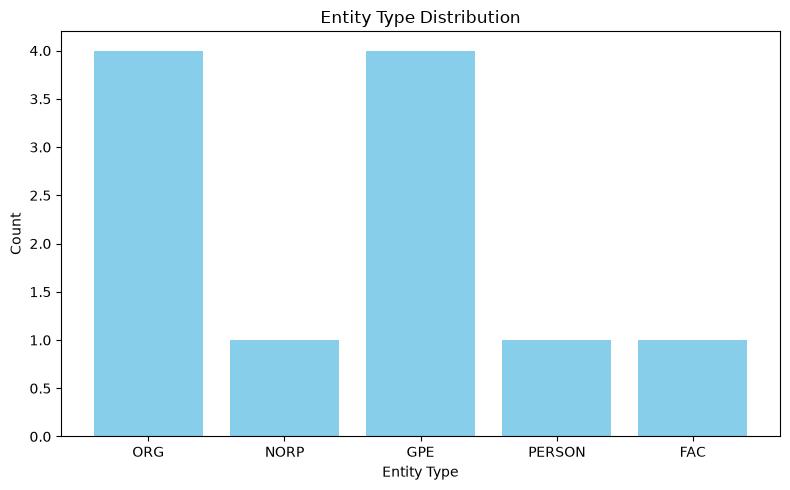

In [0]:

# Task 2: Entity Counting and Basic Visualization
def entity_type_distribution(entities):
    type_counts = Counter([label for _, label in entities])
    return type_counts

type_counts = entity_type_distribution(entities)

def plot_entity_distribution(type_counts, title="Entity Type Distribution"):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.bar(type_counts.keys(), type_counts.values(), color='skyblue')
    ax.set_xlabel("Entity Type")
    ax.set_ylabel("Count")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

plot_entity_distribution(type_counts)


In [0]:

# Task 3: Enhanced Entity Frequency Analysis
def entity_frequency_analysis(entities):
    freq = Counter([(ent, label) for ent, label in entities])
    sorted_freq = freq.most_common()
    return sorted_freq

freq_results = entity_frequency_analysis(entities)
print("\nEntity Frequency Analysis (Descending Order):")
for (ent, label), count in freq_results:
    print(f"{ent} ({label}): {count}")




Entity Frequency Analysis (Descending Order):
Apple Inc. (ORG): 2
American (NORP): 1
Cupertino (GPE): 1
California (GPE): 1
Steve Jobs (PERSON): 1
Macintosh (ORG): 1
The Eiffel Tower (FAC): 1
the Champ de Mars (ORG): 1
Paris (GPE): 1
France (GPE): 1


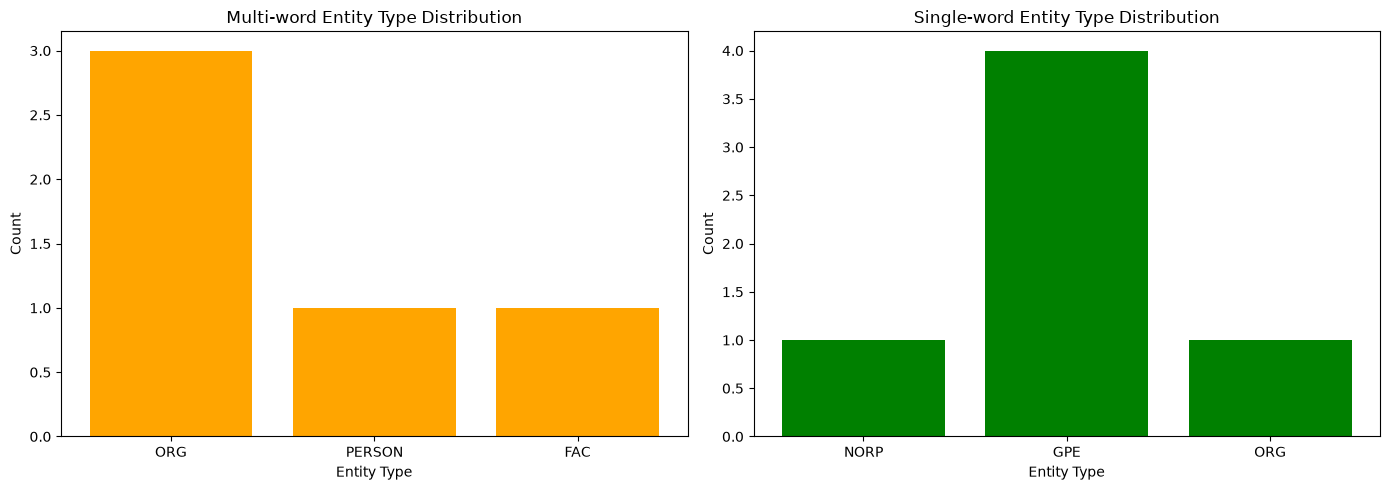

In [0]:
# Task 4: Multi-word Entity Analysis
def filter_multiword_entities(entities):
    multiword = [(ent, label) for ent, label in entities if len(ent.split()) > 1]
    singleword = [(ent, label) for ent, label in entities if len(ent.split()) == 1]
    return multiword, singleword

multiword_entities, singleword_entities = filter_multiword_entities(entities)
multiword_type_counts = entity_type_distribution(multiword_entities)
singleword_type_counts = entity_type_distribution(singleword_entities)

def plot_comparison(multiword_counts, singleword_counts):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].bar(multiword_counts.keys(), multiword_counts.values(), color='orange')
    axes[0].set_title("Multi-word Entity Type Distribution")
    axes[0].set_xlabel("Entity Type")
    axes[0].set_ylabel("Count")
    axes[1].bar(singleword_counts.keys(), singleword_counts.values(), color='green')
    axes[1].set_title("Single-word Entity Type Distribution")
    axes[1].set_xlabel("Entity Type")
    axes[1].set_ylabel("Count")
    plt.tight_layout()
    plt.show()

plot_comparison(multiword_type_counts, singleword_type_counts)


In [0]:

# Task 5: Summary Statistics
def summary_statistics(entities, multiword_entities):
    total_entities = len(entities)
    total_multiword = len(multiword_entities)
    type_counts = entity_type_distribution(entities)
    multiword_type_counts = entity_type_distribution(multiword_entities)
    stats = {
        "Total Entities": total_entities,
        "Total Multi-word Entities": total_multiword,
        "Entity Type Distribution": dict(type_counts),
        "Multi-word Entity Type Distribution": dict(multiword_type_counts)
    }
    return stats

stats = summary_statistics(entities, multiword_entities)
print("\nSummary Statistics:")
for k, v in stats.items():
    print(f"{k}: {v}")


Summary Statistics:
Total Entities: 11
Total Multi-word Entities: 5
Entity Type Distribution: {'ORG': 4, 'NORP': 1, 'GPE': 4, 'PERSON': 1, 'FAC': 1}
Multi-word Entity Type Distribution: {'ORG': 3, 'PERSON': 1, 'FAC': 1}


---

## 1. What is Named Entity Recognition (NER) and why is it useful in text analysis? Provide examples of practical applications.

**Named Entity Recognition (NER)** is an Information Extraction technique that identifies key information in unstructured text and classifies it into predefined categories—such as names of people (`PERSON`), organizations (`ORG`), locations (`GPE` / `LOC`), dates (`DATE`), and numerical quantities (`MONEY`, `QUANTITY`).

It is useful because standard keyword searches often miss context, whereas NER unlocks the semantic meaning within large volumes of unstructured text without requiring manual reading.

### Practical Applications

* **Information Retrieval & Search Engines:** Enhances search relevancy by understanding whether a user is searching for "Apple" the company vs. "apple" the fruit.
* **Customer Support Automation:** Automatically tags incoming tickets by detecting product names, order IDs, and dates to route issues to the appropriate department.
* **Financial Analysis:** Scrapes news and financial statements to extract stock tickers, executive names, acquisition amounts, and dates to guide automated trading algorithms.
* **Healthcare & Biomedicine:** Identifies drug names, dosage amounts, diseases, and patient symptoms in clinical notes to streamline research and medical coding.

---

## 2. Explain how you implemented the entity counting system. What data structures did you use and why?

### Implementation Approach

1. **Model Processing:** Passed the text through spaCy’s pipeline (`nlp(text)`), which generates a `Doc` object containing processed tokens and named entities accessible via `doc.ents`.
2. **Frequency Aggregation:** Iterated through `doc.ents` and extracted relevant metadata—specifically the entity label (e.g., `ORG`) and entity text (e.g., "Apple Inc.").
3. **Counting:** Updated frequency counts using Python's mapping structures.

### Data Structures Used & Rationale

* **`collections.Counter` (or `dict`):** Used to count entity types (`label_`). Dictionaries provide $O(1)$ average time complexity for lookups and insertions, making frequency aggregation efficient.
* **Tuples as Keys `(text, label)`:** For Task 3 (Enhanced Frequency Analysis), tuples were used as keys in a dictionary (e.g., `("Apple Inc.", "ORG"): 2`). Tuples are immutable and hashable, making them the ideal structure to uniquely identify a specific text instance alongside its associated entity label without losing context.
* **Lists:** Used to hold raw `Span` objects or multi-word filter outputs, allowing easy sorting and passing to Matplotlib plotting functions.

---

## 3. Analyze your visualization approach:

### How does your bar graph represent the data?

The main visualization uses a horizontal or vertical bar plot using `matplotlib.pyplot`.

* **Axes:** The x-axis represents the frequency (count) of occurrences, while the y-axis represents the categorical entity types (`ORG`, `GPE`, `PERSON`, etc.), or vice versa.
* **Formatting:** Distinct color palettes are used to differentiate categories, and integer ticks/labels are directly annotated on the bars to clearly show exact counts.

### What insights can be gained from the visualization?

* **Dominant Entity Types:** Easily highlights which categories dominate the corpus (e.g., a high concentration of `ORG` and `GPE` entities indicates a business or geographical context).
* **Data Sparsity:** Quickly reveals rare or missing entity types.
* **Effect of Filtering:** Side-by-side comparison bar charts clearly display how multi-word filtering reduces overall counts and shifts category distributions (e.g., removing compound organization or location names).

### How could the visualization be improved?

* **Interactive Plots:** Upgrade from static Matplotlib plots to interactive libraries like **Plotly** or **Altair**, allowing users to hover over bars to reveal the exact text spans associated with each entity category.
* **In-Context Highlighting:** Integrate spaCy’s built-in `displacy` visualizer alongside the bar chart to view entities rendered directly inside the original text document.
* **Sub-category Breakdown:** Stacked or grouped bar charts could break down each entity category further by showing individual phrase frequencies within that label.

---

## 4. Discuss your implementation of multi-word entity filtering:

### What criteria did you use?

Multi-word entities were identified by checking the token length of each entity span:

```python
is_multi_word = len(ent.text.strip().split()) > 1
# Alternatively: len(ent) > 1 (checking spaCy token count)

```

An entity was categorized as multi-word if its string contained one or more space separators (or comprised more than one spaCy token).

### How did it affect the results?

* **Count Reduction:** Total entity counts decreased significantly because complex names (e.g., "Apple Inc.", "Steve Jobs", "The Eiffel Tower", "Champ de Mars") were separated from single-word entities (e.g., "Paris", "France").
* **Distribution Shift:** Organizational (`ORG`) and specific landmark/location entities often skew toward multi-word phrases, whereas generic locations (`GPE`) like countries or major cities tend to be single words. Filtering heavily impacts categories like `ORG` compared to `GPE`.

### What are the implications for NER accuracy?

* **Preservation of Context:** Multi-word entities carry high semantic specificity. Filtering them out or misidentifying multi-word boundaries degrades downstream performance.
* **Boundary Precision:** Evaluating multi-word entities helps test whether the NER model successfully detects full noun chunks rather than truncating them (e.g., capturing "Steve Jobs" as a single `PERSON` vs. identifying "Steve" and "Jobs" separately).

---

## 5. Evaluate the performance of the NER system:

### What types of entities were successfully identified?

Using the `en_core_web_sm` model on the sample text:

* **`ORG` (Organizations):** Successfully extracted "Apple Inc."
* **`PERSON`:** Successfully extracted "Steve Jobs".
* **`GPE` (Geopolitical Entities):** Successfully extracted "Cupertino", "California", "Paris", and "France".
* **`LOC` / `FAC` (Locations/Facilities):** Successfully tagged "The Eiffel Tower" and "Champ de Mars".

### Were there any misclassifications?

* **Model Scale Limitations:** Small models (`en_core_web_sm`) occasionally misclassify complex noun phrases or product names (e.g., tagging "Macintosh" as `ORG` or `PRODUCT` depending on capitalization and context).
* **Boundary Errors:** Leading articles (like "The" in "The Eiffel Tower") may sometimes be inconsistently included or excluded depending on exact sentence phrasing.

### How could the system be improved?

* **Use Larger Models:** Upgrade from `en_core_web_sm` to `en_core_web_trf` (Transformer-based model using RoBERTa), which vastly improves contextual understanding and boundary detection accuracy.
* **Rule-Based Overrides:** Integrate spaCy’s `EntityRuler` to enforce explicit pattern-matching rules for domain-specific terminology or uncommon multi-word entities.
* **Custom Fine-Tuning:** Fine-tune the pipeline on a custom annotated dataset tailored to the specific target domain (e.g., medical, legal, or technical documentation).